# Visualizing Network Data with Python

**A practical teaching notebook using Pandas, NetworkX, Matplotlib and Plotly**

## Learning objectives

By the end of this notebook, you will be able to:

1. Explain nodes, edges, degree, weights and direction in a network.
2. Read and create an edge-list dataset.
3. Build undirected, directed, weighted and bipartite networks.
4. Visualize networks using different layouts.
5. Customize node size, node colour, edge width, labels and arrows.
6. Create an adjacency-matrix heatmap.
7. Calculate degree, betweenness and closeness centrality.
8. Detect and visualize communities.
9. Build an interactive network visualization using Plotly.

> **Dataset note:** The people, connections and interaction values in this notebook are synthetic teaching data. They do not describe real individuals or organizations.


## 1. What is network data?

Network data describes **entities and the relationships between them**.

A network is made of two basic components:

- **Node (vertex):** an entity, such as a person, airport, computer or protein.
- **Edge (link):** a relationship or connection between two nodes, such as friendship, a flight route, communication or a molecular interaction.

For example, if A is connected to B and B is connected to C, the network contains three nodes and two edges.

### Common types of networks

| Network type | Meaning | Example |
|---|---|---|
| Undirected | A connection has no direction | Mutual friendship |
| Directed | A connection has a direction | A follows B |
| Weighted | Each connection has a numerical strength or cost | Number of messages |
| Unweighted | A connection is either present or absent | A road exists |
| Bipartite | Nodes belong to two distinct groups; edges connect across groups | Students and courses |

### Important distinction

A network drawing is not automatically a map. Unless coordinates are supplied, the positions of nodes are chosen by a layout algorithm. Their positions usually do not represent physical location.


## 2. Install and import the libraries

We will use:

- **Pandas** to store and inspect edge-list data.
- **NetworkX** to construct and analyze networks.
- **Matplotlib** to draw static network diagrams.
- **Plotly** to create interactive network diagrams.
- **Seaborn** to display an adjacency matrix as a heatmap.

If a library is missing in your environment, run the installation command below.


In [1]:
# If needed, uncomment and run:
# %pip install pandas numpy networkx matplotlib seaborn plotly

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

print("Pandas:", pd.__version__)
print("NetworkX:", nx.__version__)


Pandas: 2.2.2
NetworkX: 3.5


## 3. How is network data stored?

A common format is an **edge list**. Each row represents one connection.

For example:

| Source | Target | Weight |
|---|---|---:|
| A | B | 5 |
| A | C | 3 |
| B | C | 2 |

- `Source` is the starting node.
- `Target` is the node at the other end of the connection.
- `Weight` is the strength or amount associated with the connection.

The same information can also be stored as an **adjacency matrix**. Rows and columns represent nodes. A non-zero entry indicates a connection; in a weighted network, the entry can store the edge weight.


## 4. Generate a synthetic social network dataset

We will create a fictional network with three friendship groups and a few connections between groups. The structure makes it useful for studying centrality and community detection.

The `Weight` column represents the frequency of interaction. For this undirected example, an edge means that two people interact; the weight records the interaction strength.


In [2]:
# Synthetic edge list: Source, Target and interaction strength
edges = [
    # Group 1
    ("A", "B", 8), ("A", "C", 5), ("B", "C", 7),
    ("B", "D", 6), ("C", "D", 4), ("C", "E", 5),
    ("D", "E", 8),

    # Group 2
    ("F", "G", 7), ("F", "H", 6), ("G", "H", 9),
    ("G", "I", 5), ("H", "I", 7), ("H", "J", 4),
    ("I", "J", 8),

    # Group 3
    ("K", "L", 8), ("K", "M", 6), ("L", "M", 7),
    ("L", "N", 5), ("M", "N", 9),

    # Connections between groups
    ("E", "F", 3), ("D", "G", 2), ("J", "K", 3)
]

network_df = pd.DataFrame(
    edges,
    columns=["Source", "Target", "Weight"]
)

display(network_df)


,Source,Target,Weight
0,A,B,8
1,A,C,5
2,B,C,7
3,B,D,6
4,C,D,4
5,C,E,5
6,D,E,8
7,F,G,7
8,F,H,6
9,G,H,9


In [3]:
print("Number of rows (edges):", len(network_df))
print("Unique nodes:", sorted(set(network_df["Source"]) | set(network_df["Target"])))
print("Number of unique nodes:", len(set(network_df["Source"]) | set(network_df["Target"])))
print("Total edge weight:", network_df["Weight"].sum())


Number of rows (edges): 22
Unique nodes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N']
Number of unique nodes: 14
Total edge weight: 132


## 5. Build an undirected weighted graph

NetworkX provides `nx.Graph()` for an undirected graph.

In an undirected graph, the connection A—B is the same as B—A. We add each row of the edge list to the graph and store its weight as an edge attribute.


In [4]:
G = nx.Graph()

for _, row in network_df.iterrows():
    G.add_edge(
        row["Source"],
        row["Target"],
        weight=row["Weight"]
    )

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Node labels:", list(G.nodes()))
print("Edges with attributes:")
print(list(G.edges(data=True)))


Nodes: 14
Edges: 22
Node labels: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N']
Edges with attributes:
[('A', 'B', {'weight': 8}), ('A', 'C', {'weight': 5}), ('B', 'C', {'weight': 7}), ('B', 'D', {'weight': 6}), ('C', 'D', {'weight': 4}), ('C', 'E', {'weight': 5}), ('D', 'E', {'weight': 8}), ('D', 'G', {'weight': 2}), ('E', 'F', {'weight': 3}), ('F', 'G', {'weight': 7}), ('F', 'H', {'weight': 6}), ('G', 'H', {'weight': 9}), ('G', 'I', {'weight': 5}), ('H', 'I', {'weight': 7}), ('H', 'J', {'weight': 4}), ('I', 'J', {'weight': 8}), ('J', 'K', {'weight': 3}), ('K', 'L', {'weight': 8}), ('K', 'M', {'weight': 6}), ('L', 'M', {'weight': 7}), ('L', 'N', {'weight': 5}), ('M', 'N', {'weight': 9})]


### Inspect node and edge information

NetworkX stores nodes and edges separately. Edge attributes such as `weight` can be retrieved from the graph.


In [5]:
# Neighbours of a selected node
print("Neighbours of A:", list(G.neighbors("A")))

# Weight of a selected edge
print("Weight of edge A-B:", G["A"]["B"]["weight"])

# Degree of every node
print("Degree:", dict(G.degree()))


Neighbours of A: ['B', 'C']
Weight of edge A-B: 8
Degree: {'A': 2, 'B': 3, 'C': 4, 'D': 4, 'E': 3, 'F': 3, 'G': 4, 'H': 4, 'I': 3, 'J': 3, 'K': 3, 'L': 3, 'M': 3, 'N': 2}


# Part A — Basic network visualization

## 6. Draw the first network

NetworkX can draw a graph with a few lines of code. The layout determines where nodes are placed.


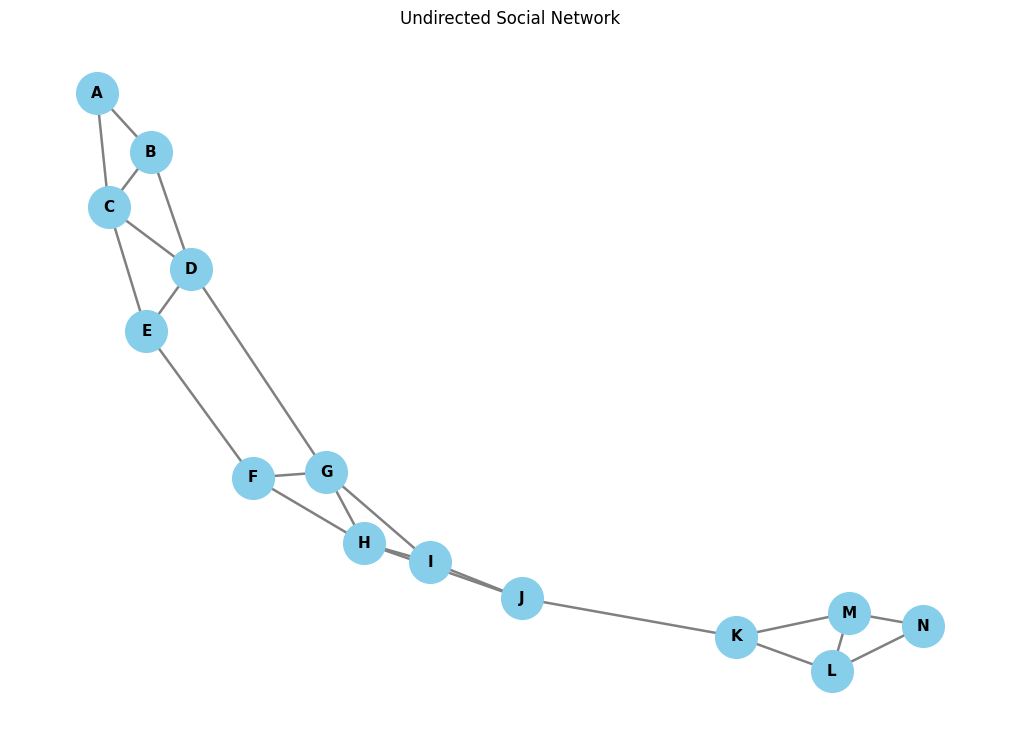

In [6]:
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 7))
nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="skyblue",
    node_size=900,
    font_size=11,
    font_weight="bold",
    edge_color="gray",
    width=1.8
)
plt.title("Undirected Social Network")
plt.axis("off")
plt.show()


### How to read this plot

- Each circle is a person (node).
- Each line is a relationship (edge).
- A node with many lines has a high degree.
- The drawing position is determined by the layout, not by a person's real-world location.

### What is spring layout?

`nx.spring_layout()` is a force-directed layout. It approximates a system in which connected nodes attract one another and nodes repel one another. It tries to produce a readable arrangement.

The `seed` makes the layout reproducible. Without a fixed seed, the arrangement can change between runs.


## 7. Compare different network layouts

The same network can look different under different layout algorithms. The connections have not changed; only the node positions have changed.

Common layouts:

| Function | General arrangement |
|---|---|
| `spring_layout()` | Force-directed |
| `circular_layout()` | Nodes around a circle |
| `kamada_kawai_layout()` | Distance-oriented force layout |
| `shell_layout()` | Nodes in concentric shells |
| `spectral_layout()` | Uses eigenvectors of a graph matrix |


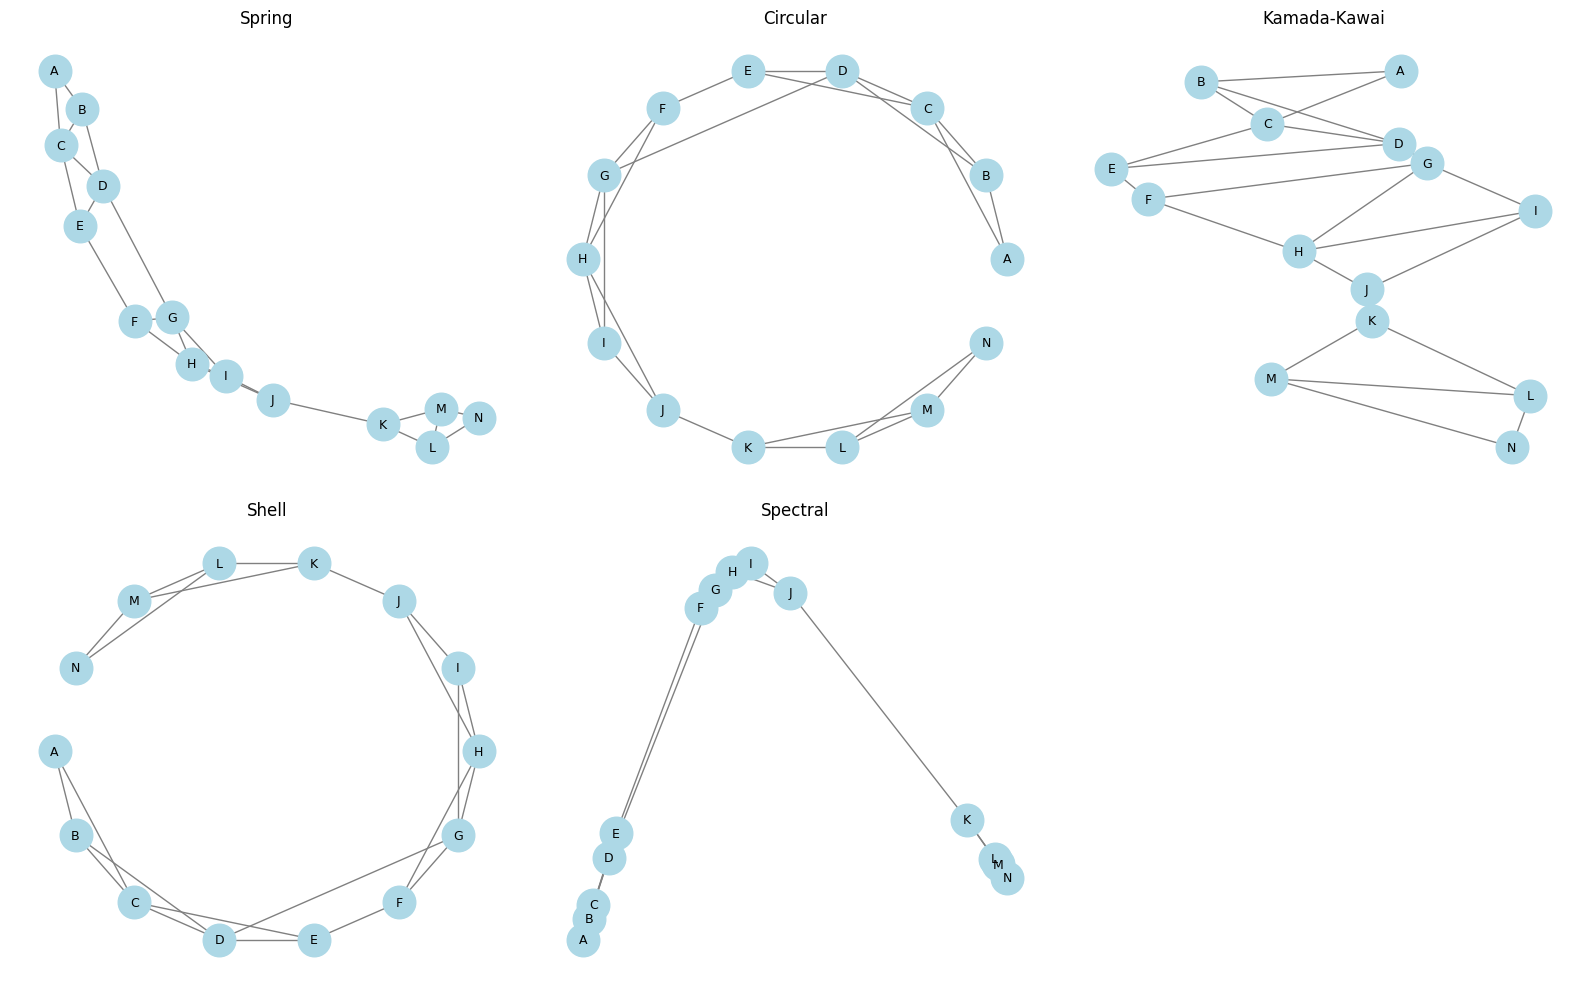

In [7]:
layouts = {
    "Spring": nx.spring_layout(G, seed=42),
    "Circular": nx.circular_layout(G),
    "Kamada-Kawai": nx.kamada_kawai_layout(G),
    "Shell": nx.shell_layout(G),
    "Spectral": nx.spectral_layout(G)
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, (layout_name, positions) in zip(axes, layouts.items()):
    nx.draw(
        G,
        positions,
        ax=ax,
        with_labels=True,
        node_color="lightblue",
        node_size=550,
        font_size=9,
        edge_color="gray"
    )
    ax.set_title(layout_name)
    ax.axis("off")

axes[-1].axis("off")
plt.tight_layout()
plt.show()


### A note about layout interpretation

A node appearing near the centre of a spring layout is not automatically the most important node. Layout position is a visual arrangement. Use network measures such as degree or betweenness centrality when making analytical claims.


# Part B — Customize a network graph

## 8. Change node size using degree

**Degree** is the number of edges connected to a node in an undirected network.

For example, if node A is connected to B, C and D, its degree is 3.

We can use degree to make highly connected nodes larger.


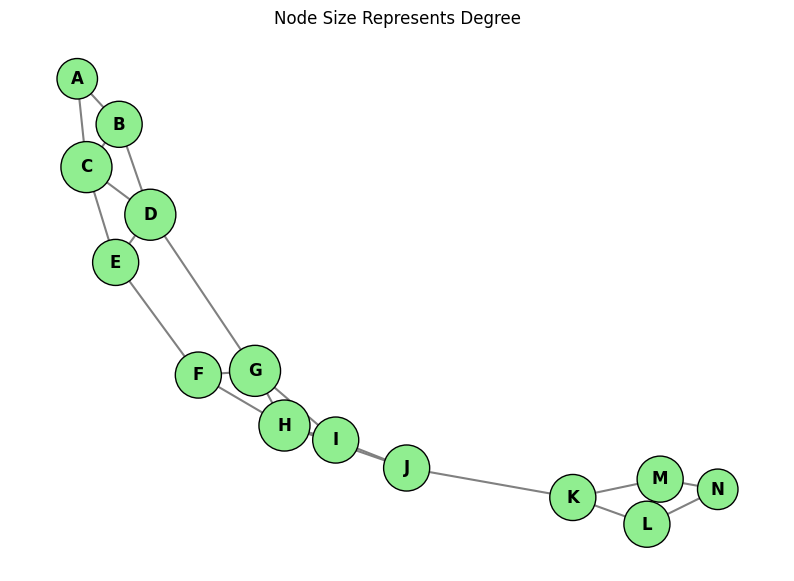

In [8]:
degree_dict = dict(G.degree())

node_sizes = [
    350 + degree_dict[node] * 250
    for node in G.nodes()
]

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(G, pos, edge_color="gray", width=1.5)
nx.draw_networkx_nodes(
    G, pos,
    node_size=node_sizes,
    node_color="lightgreen",
    edgecolors="black"
)
nx.draw_networkx_labels(G, pos, font_weight="bold")

plt.title("Node Size Represents Degree")
plt.axis("off")
plt.show()


**Interpretation:** Larger nodes have more direct connections. Node size is a visual encoding of degree in this plot.

The size formula above adds a base size so that nodes with few connections remain visible. It is a visual choice, not a mathematical requirement.


## 9. Change edge thickness using weight

An edge weight can represent interaction frequency, transaction volume, collaboration strength or another numerical quantity.

Here, thicker edges represent stronger interactions.


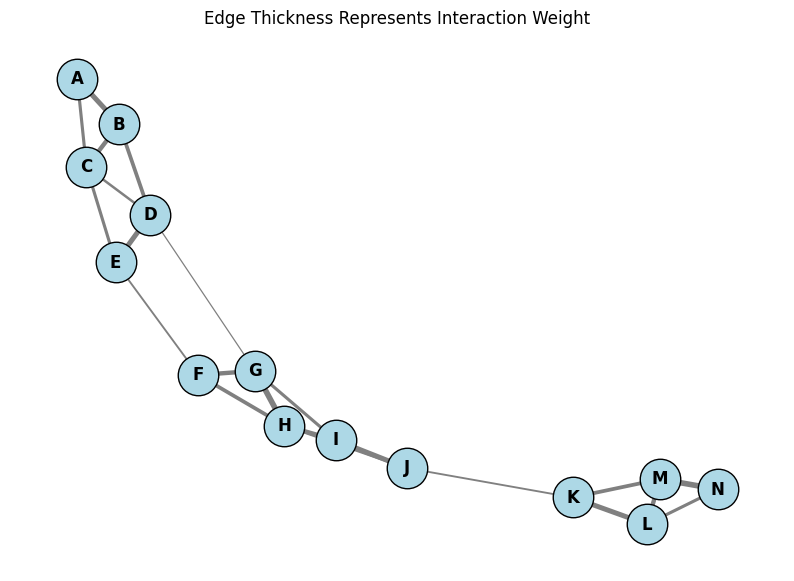

In [29]:
pos = nx.spring_layout(G, seed=42)

edge_widths = [
    G[u][v]["weight"] * 0.45
    for u, v in G.edges()
]

plt.figure(figsize=(10, 7))
nx.draw_networkx_nodes(
    G, pos,
    node_size=850,
    node_color="lightblue",
    edgecolors="black"
)
nx.draw_networkx_labels(G, pos, font_weight="bold")
nx.draw_networkx_edges(
    G, pos,
    width=edge_widths,
    edge_color="gray"
)

plt.title("Edge Thickness Represents Interaction Weight")
plt.axis("off")
plt.show()


**Interpretation:** A thicker line indicates a higher edge weight. This only makes sense if the weight has a meaningful interpretation and the legend or explanation is clear.

Be careful: in some applications, a large weight means a stronger connection; in others, such as travel time or distance, a large weight means a greater cost.


## 10. Change node colour using a numerical measure

We can colour nodes by their degree. A colour scale makes the numerical differences easier to see.


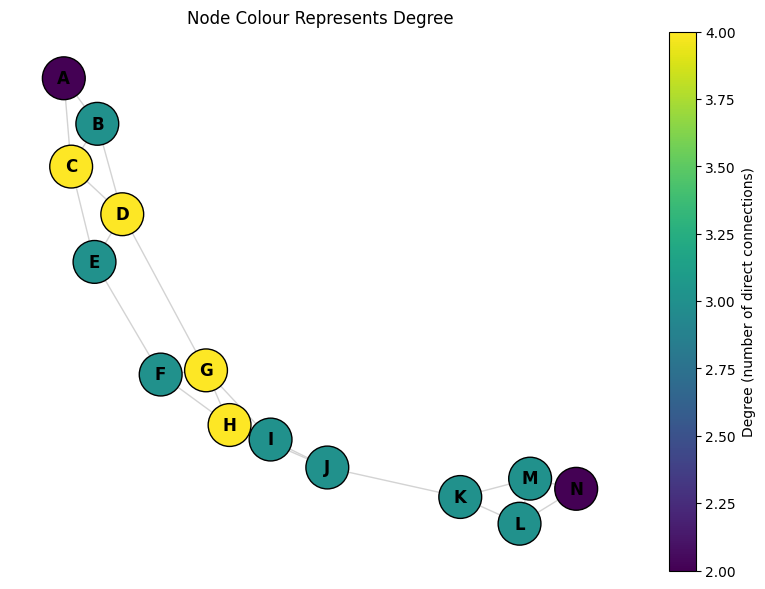

In [30]:
degree_values = [G.degree(node) for node in G.nodes()]
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(G, pos, edge_color="lightgray")
nodes = nx.draw_networkx_nodes(
    G, pos,
    node_size=950,
    node_color=degree_values,
    cmap=plt.cm.viridis,
    edgecolors="black"
)
nx.draw_networkx_labels(G, pos, font_weight="bold")

plt.colorbar(nodes, label="Degree (number of direct connections)")
plt.title("Node Colour Represents Degree")
plt.axis("off")
plt.show()


### Three encodings in one visualization

A network diagram can communicate multiple variables at once:

- Node size can represent degree.
- Node colour can represent centrality or community.
- Edge thickness can represent relationship strength.

Avoid encoding too many variables at once. A chart that is visually busy can be harder to interpret than a simpler one.


## 11. Add labels and improve readability

Labels help identify nodes, but too many labels can overlap. For a small network, show all labels. For a large network, consider labelling only selected or important nodes.


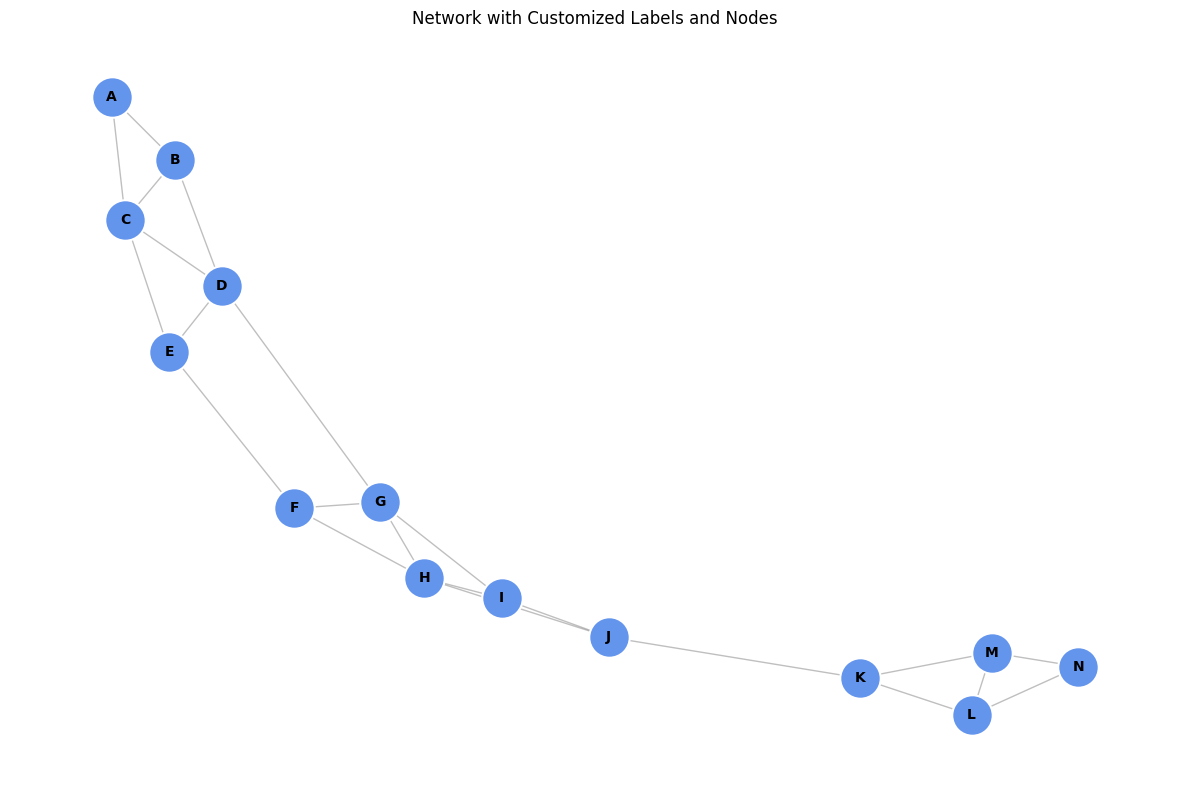

In [31]:
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(12, 8))
nx.draw_networkx_edges(G, pos, alpha=0.5, edge_color="gray")
nx.draw_networkx_nodes(
    G, pos,
    node_size=850,
    node_color="cornflowerblue",
    edgecolors="white",
    linewidths=1.5
)
nx.draw_networkx_labels(
    G, pos,
    font_size=10,
    font_weight="bold",
    font_color="black"
)

plt.title("Network with Customized Labels and Nodes")
plt.axis("off")
plt.tight_layout()
plt.show()


# Part C — Network types

## 12. Directed networks

A directed network has edges with a direction. For example, A may send a message to B without B sending a message back.

Use `nx.DiGraph()` to create a directed graph.


In [32]:
directed_edges = [
    ("A", "B", 10),
    ("A", "C", 5),
    ("B", "C", 8),
    ("C", "D", 12),
    ("D", "A", 4),
    ("D", "E", 7),
    ("E", "B", 6)
]

DG = nx.DiGraph()

for source, target, weight in directed_edges:
    DG.add_edge(source, target, weight=weight)

print("Directed edges:")
print(list(DG.edges(data=True)))


Directed edges:
[('A', 'B', {'weight': 10}), ('A', 'C', {'weight': 5}), ('B', 'C', {'weight': 8}), ('C', 'D', {'weight': 12}), ('D', 'A', {'weight': 4}), ('D', 'E', {'weight': 7}), ('E', 'B', {'weight': 6})]


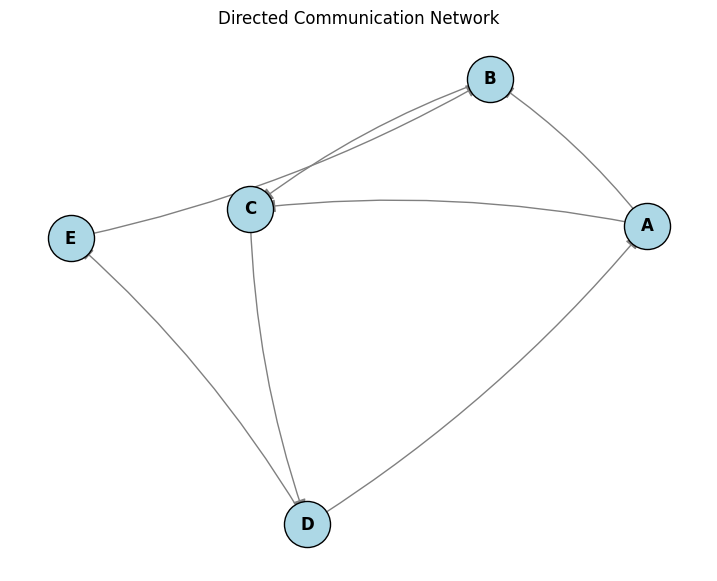

In [13]:
pos_d = nx.spring_layout(DG, seed=10)

plt.figure(figsize=(9, 7))
nx.draw_networkx_nodes(
    DG, pos_d,
    node_color="lightblue",
    node_size=1100,
    edgecolors="black"
)
nx.draw_networkx_labels(DG, pos_d, font_weight="bold")
nx.draw_networkx_edges(
    DG, pos_d,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=20,
    edge_color="gray",
    connectionstyle="arc3,rad=0.08"
)

plt.title("Directed Communication Network")
plt.axis("off")
plt.show()


### In-degree and out-degree

In a directed graph:

- **In-degree:** Number of edges entering a node.
- **Out-degree:** Number of edges leaving a node.

In a social-media example, in-degree could represent the number of incoming follows, while out-degree could represent the number of accounts a person follows. This interpretation depends on how the edge direction is defined.


In [14]:
degree_summary = pd.DataFrame({
    "Node": list(DG.nodes()),
    "In_Degree": [DG.in_degree(n) for n in DG.nodes()],
    "Out_Degree": [DG.out_degree(n) for n in DG.nodes()]
})

display(degree_summary)


,Node,In_Degree,Out_Degree
0,A,1,2
1,B,2,1
2,C,2,1
3,D,1,2
4,E,1,1


## 13. Weighted versus unweighted networks

A weighted network stores a value on each edge. An unweighted network only records whether the edge exists.

We can create an unweighted version of our graph by ignoring the weight attribute. The topology (which nodes are connected) stays the same.


In [15]:
# Unweighted graph with the same connections
G_unweighted = nx.Graph()
G_unweighted.add_edges_from(network_df[["Source", "Target"]].itertuples(index=False, name=None))

print("Weighted graph edges:", G.number_of_edges())
print("Unweighted graph edges:", G_unweighted.number_of_edges())
print("Same node set:", set(G.nodes()) == set(G_unweighted.nodes()))


Weighted graph edges: 22
Unweighted graph edges: 22
Same node set: True


## 14. Bipartite networks

A bipartite network has two distinct node groups. Edges connect nodes from one group to nodes in the other group.

Example: students and courses. A student is connected to a course when they are enrolled in it.

We will create a small student-course dataset.


In [16]:
enrolments = pd.DataFrame({
    "Student": ["S1", "S1", "S2", "S2", "S2", "S3", "S3", "S4", "S4"],
    "Course":  ["Python", "Statistics", "Python", "Databases", "Networks",
                "Statistics", "Networks", "Python", "Databases"]
})

display(enrolments)


,Student,Course
0,S1,Python
1,S1,Statistics
2,S2,Python
3,S2,Databases
4,S2,Networks
5,S3,Statistics
6,S3,Networks
7,S4,Python
8,S4,Databases


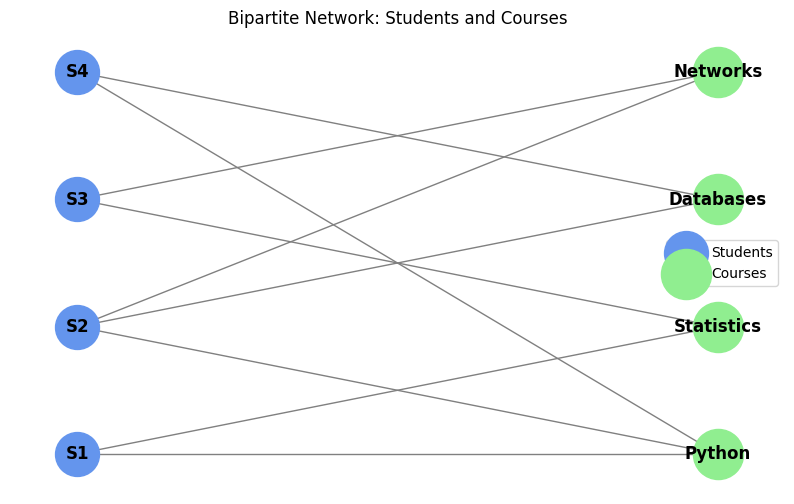

In [17]:
B = nx.Graph()

students = enrolments["Student"].unique().tolist()
courses = enrolments["Course"].unique().tolist()

B.add_nodes_from(students, bipartite="students")
B.add_nodes_from(courses, bipartite="courses")
B.add_edges_from(enrolments.itertuples(index=False, name=None))

# Place the two node sets in separate columns
bipartite_pos = {}
bipartite_pos.update({node: (0, i) for i, node in enumerate(students)})
bipartite_pos.update({node: (1, i) for i, node in enumerate(courses)})

plt.figure(figsize=(10, 6))
nx.draw_networkx_edges(B, bipartite_pos, edge_color="gray")
nx.draw_networkx_nodes(
    B, bipartite_pos,
    nodelist=students,
    node_color="cornflowerblue",
    node_size=1000,
    label="Students"
)
nx.draw_networkx_nodes(
    B, bipartite_pos,
    nodelist=courses,
    node_color="lightgreen",
    node_size=1300,
    label="Courses"
)
nx.draw_networkx_labels(B, bipartite_pos, font_weight="bold")
plt.legend()
plt.title("Bipartite Network: Students and Courses")
plt.axis("off")
plt.show()


**Interpretation:** The two node sets are visually separated. A line indicates that a student is enrolled in a particular course. This type of network is useful for recommendation systems, customer-product analysis and affiliation networks.


# Part D — Adjacency matrix visualization

## 15. Create an adjacency matrix

An adjacency matrix is a square table in which each row and column corresponds to a node.

For an unweighted graph:
- 1 means an edge exists.
- 0 means no edge exists.

For a weighted graph, the matrix can contain edge weights. For an undirected graph, the matrix is symmetric.


In [18]:
adjacency = nx.to_pandas_adjacency(
    G,
    nodelist=sorted(G.nodes()),
    weight="weight",
    dtype=int
)

display(adjacency)


,A,B,C,D,E,F,G,H,I,J,K,L,M,N
A,0,8,5,0,0,0,0,0,0,0,0,0,0,0
B,8,0,7,6,0,0,0,0,0,0,0,0,0,0
C,5,7,0,4,5,0,0,0,0,0,0,0,0,0
D,0,6,4,0,8,0,2,0,0,0,0,0,0,0
E,0,0,5,8,0,3,0,0,0,0,0,0,0,0
F,0,0,0,0,3,0,7,6,0,0,0,0,0,0
G,0,0,0,2,0,7,0,9,5,0,0,0,0,0
H,0,0,0,0,0,6,9,0,7,4,0,0,0,0
I,0,0,0,0,0,0,5,7,0,8,0,0,0,0
J,0,0,0,0,0,0,0,4,8,0,3,0,0,0


## 16. Visualize the adjacency matrix as a heatmap

A heatmap uses colour intensity to represent values in a matrix. Darker or more intense cells can indicate stronger edge weights, depending on the colour scale.


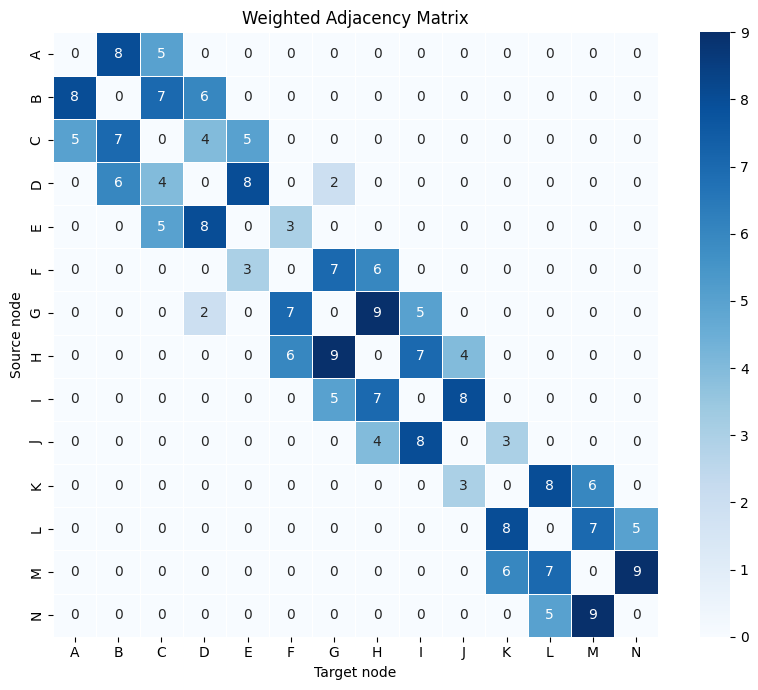

In [19]:
plt.figure(figsize=(9, 7))
sns.heatmap(
    adjacency,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    square=True
)
plt.title("Weighted Adjacency Matrix")
plt.xlabel("Target node")
plt.ylabel("Source node")
plt.tight_layout()
plt.show()


### When is an adjacency matrix useful?

- It is often clearer than a node-link diagram for dense networks.
- It makes it easy to inspect which pairs are connected.
- It can reveal blocks or clusters of connections.
- It is useful when the exact pairwise connection pattern matters.

A node-link diagram is often more intuitive for a small sparse network. An adjacency matrix can be more readable when there are many edges.


# Part E — Network analysis

Visualization shows the structure of a network. Network analysis calculates measures that help describe that structure.

## 17. Degree and degree centrality

**Degree** is the number of direct neighbours of a node in an undirected graph.

**Degree centrality** scales degree by the maximum possible number of neighbours. For a simple undirected graph with N nodes:

Degree centrality = degree / (N - 1)

The result ranges from 0 to 1.


In [20]:
degree = dict(G.degree())
degree_centrality = nx.degree_centrality(G)

degree_table = pd.DataFrame({
    "Node": list(G.nodes()),
    "Degree": [degree[n] for n in G.nodes()],
    "Degree_Centrality": [degree_centrality[n] for n in G.nodes()]
}).sort_values("Degree", ascending=False)

display(degree_table)


,Node,Degree,Degree_Centrality
3,D,4,0.307692
2,C,4,0.307692
7,H,4,0.307692
6,G,4,0.307692
4,E,3,0.230769
1,B,3,0.230769
10,K,3,0.230769
5,F,3,0.230769
8,I,3,0.230769
9,J,3,0.230769


**Interpretation:** A high-degree node has many direct connections. It may be a highly connected person, a frequently used airport or a protein with many recorded interactions. High degree does not automatically mean the node is influential in every sense.


## 18. Betweenness centrality

Betweenness centrality measures how often a node lies on shortest paths between other pairs of nodes.

A node with high betweenness may act as a bridge between parts of the network.

For example, a researcher who connects two otherwise separate collaboration groups may have high betweenness.


In [21]:
betweenness = nx.betweenness_centrality(G, normalized=True)

betweenness_table = pd.DataFrame({
    "Node": list(G.nodes()),
    "Betweenness_Centrality": [betweenness[n] for n in G.nodes()]
}).sort_values("Betweenness_Centrality", ascending=False)

display(betweenness_table)


,Node,Betweenness_Centrality
9,J,0.461538
10,K,0.384615
6,G,0.339744
7,H,0.316239
3,D,0.288462
8,I,0.143162
5,F,0.136752
2,C,0.102564
4,E,0.085470
11,L,0.070513


## 19. Closeness centrality

Closeness centrality is based on shortest-path distances from one node to other nodes. A node with high closeness can reach other nodes through relatively few steps.

For disconnected networks, NetworkX calculates closeness using reachable nodes, with a correction based on the size of the reachable component.


In [22]:
closeness = nx.closeness_centrality(G)

closeness_table = pd.DataFrame({
    "Node": list(G.nodes()),
    "Closeness_Centrality": [closeness[n] for n in G.nodes()]
}).sort_values("Closeness_Centrality", ascending=False)

display(closeness_table)


,Node,Closeness_Centrality
7,H,0.433333
6,G,0.419355
8,I,0.406250
9,J,0.393939
5,F,0.393939
3,D,0.371429
4,E,0.351351
10,K,0.333333
2,C,0.309524
1,B,0.295455


## 20. Compare centrality measures

Different centrality measures answer different questions:

| Measure | Main question |
|---|---|
| Degree | How many direct connections does the node have? |
| Betweenness | How often does the node lie on shortest paths? |
| Closeness | How near is the node to the other reachable nodes? |

A node can rank highly on one measure and lower on another. There is no single universally best measure; choose one that matches the research or business question.


In [23]:
centrality_comparison = pd.DataFrame({
    "Node": list(G.nodes()),
    "Degree": [G.degree(n) for n in G.nodes()],
    "Degree_Centrality": [nx.degree_centrality(G)[n] for n in G.nodes()],
    "Betweenness": [nx.betweenness_centrality(G)[n] for n in G.nodes()],
    "Closeness": [nx.closeness_centrality(G)[n] for n in G.nodes()]
})

display(centrality_comparison.sort_values("Degree", ascending=False))


,Node,Degree,Degree_Centrality,Betweenness,Closeness
3,D,4,0.307692,0.288462,0.371429
2,C,4,0.307692,0.102564,0.309524
7,H,4,0.307692,0.316239,0.433333
6,G,4,0.307692,0.339744,0.419355
4,E,3,0.230769,0.085470,0.351351
1,B,3,0.230769,0.049145,0.295455
10,K,3,0.230769,0.384615,0.333333
5,F,3,0.230769,0.136752,0.393939
8,I,3,0.230769,0.143162,0.406250
9,J,3,0.230769,0.461538,0.393939


# Part F — Community detection

## 21. What is a community?

A community is a group of nodes with relatively dense connections within the group and fewer connections to nodes outside it.

In a social network, communities might correspond to friendship groups. In a research network, they might represent groups of researchers who collaborate frequently.

One algorithm available in NetworkX is **greedy modularity maximization**. It repeatedly merges groups in a way that seeks to increase modularity.


In [24]:
from networkx.algorithms.community import greedy_modularity_communities

communities = list(greedy_modularity_communities(G, weight="weight"))

for index, community in enumerate(communities, start=1):
    print(f"Community {index}: {sorted(community)}")


Community 1: ['A', 'B', 'C', 'D', 'E']
Community 2: ['F', 'G', 'H', 'I', 'J']
Community 3: ['K', 'L', 'M', 'N']


## 22. Visualize the detected communities

We assign a different colour to each detected community. The algorithm's result depends on the graph structure and the chosen algorithm; it is not a ground-truth label unless external evidence confirms it.


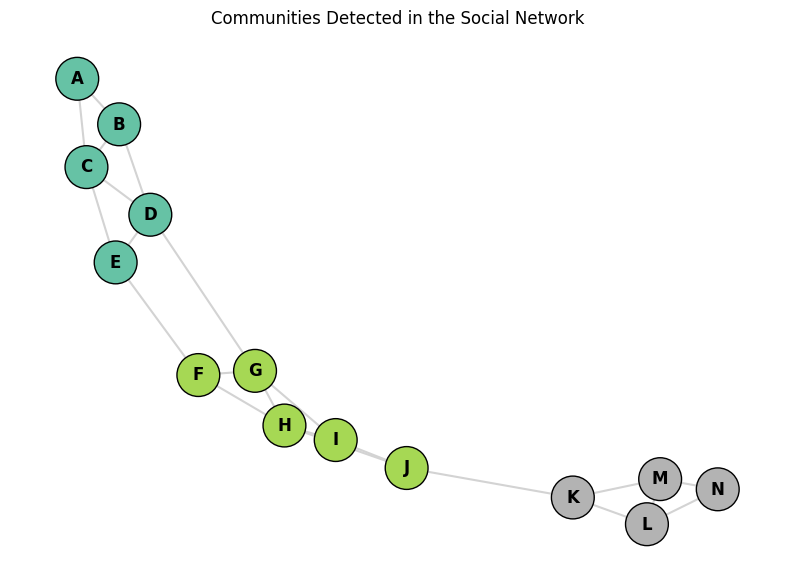

In [25]:
community_of = {}
for community_id, community in enumerate(communities):
    for node in community:
        community_of[node] = community_id

node_community_colours = [community_of[node] for node in G.nodes()]
pos = nx.spring_layout(G, seed=42, weight="weight")

plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(G, pos, edge_color="lightgray", width=1.5)
nodes = nx.draw_networkx_nodes(
    G, pos,
    node_color=node_community_colours,
    cmap=plt.cm.Set2,
    node_size=950,
    edgecolors="black"
)
nx.draw_networkx_labels(G, pos, font_weight="bold")
plt.title("Communities Detected in the Social Network")
plt.axis("off")
plt.show()


# Part G — Interactive network visualization with Plotly

## 23. Why use an interactive graph?

A static network is useful for reports and presentations. An interactive graph can help users:
- hover over a node to inspect information;
- zoom and pan;
- inspect node-level attributes;
- explore larger networks more comfortably.

The following example uses Plotly. The layout coordinates are calculated by NetworkX and then passed to Plotly.


In [26]:
# Calculate node positions once so the edges and nodes align
pos = nx.spring_layout(G, seed=42, weight="weight")

# Build one line trace for all edges
edge_x, edge_y = [], []
for u, v in G.edges():
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])

edge_trace = go.Scatter(
    x=edge_x,
    y=edge_y,
    mode="lines",
    line=dict(width=1.5, color="gray"),
    hoverinfo="none"
)

# Build node coordinates and hover labels
node_x, node_y, node_labels, hover_text, node_degrees = [], [], [], [], []

for node in G.nodes():
    x, y = pos[node]
    node_x.append(x)
    node_y.append(y)
    node_labels.append(node)
    node_degrees.append(G.degree(node))
    hover_text.append(
        f"Node: {node}<br>"
        f"Degree: {G.degree(node)}<br>"
        f"Weighted degree: {G.degree(node, weight='weight')}"
    )

node_trace = go.Scatter(
    x=node_x,
    y=node_y,
    mode="markers+text",
    text=node_labels,
    textposition="top center",
    hovertext=hover_text,
    hoverinfo="text",
    marker=dict(
        size=18,
        color=node_degrees,
        colorscale="Viridis",
        showscale=True,
        colorbar=dict(title="Degree"),
        line=dict(width=1, color="black")
    )
)

fig = go.Figure(data=[edge_trace, node_trace])
fig.update_layout(
    title="Interactive Social Network",
    showlegend=False,
    hovermode="closest",
    xaxis=dict(visible=False),
    yaxis=dict(visible=False),
    height=650,
    margin=dict(l=20, r=20, t=60, b=20)
)
fig.show()


### Optional interactive improvement: show edge weights on hover

The previous Plotly chart puts all edges into one trace for efficiency. To make each edge individually hoverable, we can instead create a separate trace per edge. This is suitable for small networks, but can become slow for very large graphs.


In [27]:
fig = go.Figure()

# Add each edge as its own trace, with its weight in the hover text
for u, v, data in G.edges(data=True):
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    weight = data["weight"]

    fig.add_trace(go.Scatter(
        x=[x0, x1],
        y=[y0, y1],
        mode="lines",
        line=dict(width=1 + weight * 0.35, color="gray"),
        hovertemplate=f"{u} — {v}<br>Interaction weight: {weight}<extra></extra>",
        showlegend=False
    ))

# Add nodes on top of the edges
fig.add_trace(go.Scatter(
    x=node_x,
    y=node_y,
    mode="markers+text",
    text=node_labels,
    textposition="top center",
    hovertext=hover_text,
    hoverinfo="text",
    marker=dict(
        size=18,
        color=node_degrees,
        colorscale="Viridis",
        showscale=True,
        colorbar=dict(title="Degree"),
        line=dict(width=1, color="black")
    ),
    showlegend=False
))

fig.update_layout(
    title="Interactive Weighted Network — Hover Over an Edge or Node",
    hovermode="closest",
    xaxis=dict(visible=False),
    yaxis=dict(visible=False),
    height=650
)
fig.show()


# Part H — Common interpretation mistakes and limitations

## 24. What to be careful about

1. **Layout is not geography:** Node position is usually calculated by an algorithm, not measured from the real world.
2. **Visual centrality is not a metric:** A node near the centre of the drawing is not necessarily the most central node mathematically.
3. **Degree is not influence:** Many connections do not always mean high influence, trust or importance.
4. **Weight needs context:** A large weight may mean strong interaction, high cost or long distance. Interpret it according to the dataset.
5. **Direction matters:** Do not use an undirected graph if the relationship has a meaningful direction.
6. **Dense networks can become cluttered:** Use filtering, aggregation, community views or adjacency matrices.
7. **Community detection is algorithm-dependent:** Different algorithms and settings can produce different partitions.
8. **Missing nodes:** If isolated entities matter, add them explicitly. An edge list alone cannot show an entity that has no connections.


## 25. A practical example: create a network from a new dataset

The steps for a new network dataset are:

1. Identify what the nodes represent.
2. Identify what counts as a connection.
3. Decide whether the connection is directed or undirected.
4. Decide whether connections have weights.
5. Build an edge list.
6. Create the appropriate graph object.
7. Choose a layout and visualize.
8. Calculate network measures that answer your question.

For example, in a research collaboration network:
- Nodes = researchers.
- Edges = co-authorship.
- Weight = number of joint publications.
- Degree = number of distinct collaborators.
- Betweenness = extent to which a researcher bridges collaboration paths.
- Communities = groups of researchers with dense collaboration links.


# Part I — Classroom exercises

## 26. Hands-on tasks

Use the generated `network_df`, `G`, `DG` and `B` objects.

### Task A — Basic network
1. Print the number of nodes and edges.
2. Identify the node with the highest degree.
3. Draw the graph using `circular_layout`.
4. Change the node colour and size.

### Task B — Weighted network
1. Draw the network with edge width proportional to `Weight`.
2. Identify the strongest edge.
3. Create a weighted adjacency matrix.
4. Plot the matrix as a heatmap.

### Task C — Directed network
1. Calculate in-degree and out-degree.
2. Identify the node with the highest out-degree.
3. Draw the directed network with arrows.

### Task D — Network analysis
1. Calculate degree centrality.
2. Calculate betweenness centrality.
3. Calculate closeness centrality.
4. Compare the rankings. Are they identical?

### Task E — Communities
1. Detect communities using greedy modularity.
2. Print the members of each community.
3. Colour nodes by their detected community.
4. Explain why the detected groups are plausible based on the edge list.


## 27. Exercise answer checks

Run the following cells after attempting the tasks. They provide checks and example solutions.


In [28]:
# Task A: node with highest degree
degree_series = pd.Series(dict(G.degree()), name="Degree")
print("Highest-degree node:")
display(degree_series.sort_values(ascending=False).head(1))

# Task B: strongest edge
strongest_edge = max(
    G.edges(data=True),
    key=lambda item: item[2]["weight"]
)
print("Strongest edge:", strongest_edge)

# Task C: node with highest out-degree
out_degree_series = pd.Series(dict(DG.out_degree()), name="Out-degree")
print("Highest out-degree node:")
display(out_degree_series.sort_values(ascending=False).head(1))

# Task D: centrality rankings
display(
    centrality_comparison.sort_values("Betweenness", ascending=False)
)

# Task E: detected communities
for i, community in enumerate(communities, start=1):
    print(f"Community {i}: {sorted(community)}")


Highest-degree node:


D    4
Name: Degree, dtype: int64

Strongest edge: ('G', 'H', {'weight': 9})
Highest out-degree node:


A    2
Name: Out-degree, dtype: int64

,Node,Degree,Degree_Centrality,Betweenness,Closeness
9,J,3,0.230769,0.461538,0.393939
10,K,3,0.230769,0.384615,0.333333
6,G,4,0.307692,0.339744,0.419355
7,H,4,0.307692,0.316239,0.433333
3,D,4,0.307692,0.288462,0.371429
8,I,3,0.230769,0.143162,0.406250
5,F,3,0.230769,0.136752,0.393939
2,C,4,0.307692,0.102564,0.309524
4,E,3,0.230769,0.085470,0.351351
11,L,3,0.230769,0.070513,0.270833


Community 1: ['A', 'B', 'C', 'D', 'E']
Community 2: ['F', 'G', 'H', 'I', 'J']
Community 3: ['K', 'L', 'M', 'N']


## 28. Quick knowledge check

Answer these questions before moving on:

1. What is the difference between a node and an edge?
2. When would you use `nx.DiGraph()` instead of `nx.Graph()`?
3. What does degree measure?
4. What does edge thickness represent in our weighted visualization?
5. Why can a node appear central in a drawing without having the highest centrality score?
6. When might an adjacency matrix be easier to read than a node-link diagram?
7. What does betweenness centrality help identify?
8. What is a bipartite network?

## 29. Summary

- Network data represents entities and their relationships.
- Nodes represent entities; edges represent connections.
- An edge list is a common way to store network relationships.
- NetworkX builds and analyzes graphs.
- Layout algorithms determine where nodes appear in a drawing.
- Node size, node colour and edge width can encode additional variables.
- Directed, undirected, weighted and bipartite networks represent different relationship structures.
- Adjacency matrices are useful for inspecting pairwise connections.
- Degree, betweenness and closeness centrality answer different questions.
- Community detection identifies groups with relatively dense internal connections.
- Plotly can make network visualizations interactive.

**Key takeaway:** A network visualization is not simply a picture of connected points. It is a way to explore the structure, strength and organization of relationships between entities.
